# PeakLoad Lens: Weather-Aware Peak Demand Forecasting and Error Analysis

**Question.** Can historical consumption and weather improve *one-hour-ahead* electricity-demand forecasts, especially during peak demand, compared with simple baselines?

**Data.** UCI *Power Consumption of Tetouan City* (Salam & El Hibaoui, 2018; CC BY 4.0), 10-minute observations from 2017. Target: **Zone 1** consumption.

**What a forecaster knows at forecast time (origin *t*).**

| Allowed | Not allowed |
|---|---|
| Consumption and weather observed at or before *t* | Any consumption or weather observed after *t* |
| Calendar fields (hour, weekday) of the *target* time, since calendars are known in advance | Actual weather during the target hour (we have no genuine weather forecasts) |

The notebook walks through: audit → target definition → splits → EDA → features → models → peak analysis → weather ablation → error investigation → conclusions. All heavy logic lives in `src/` so the notebook stays readable. Run it from the `notebooks/` folder (or the project root).

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import data_audit as da
import forecasting as fc

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("Project root:", ROOT)

Project root: /home/claude/PeakLoad-Lens


## 1. Dataset audit

**What we do and why.** We inspect the raw file *before* modelling. The source page says "no missing values", but a time-series forecaster also needs to know about duplicate or missing timestamps, because a "6 rows ahead" shift only equals "1 hour ahead" if the 10-minute grid is perfect.

**Common mistakes to avoid:** trusting the documentation instead of checking; parsing dates with the wrong day/month order (this file is `month/day/year`); dropping or interpolating rows without recording it.

**Expected output:** a table of checks. The raw frame is never modified; cleaning happens in a separate working frame.

In [2]:
raw = da.load_raw()          # path: data/Tetuan City power consumption.csv, or env var PEAKLOAD_DATA
print("shape:", raw.shape)
display(raw.head(3))
display(raw.dtypes.to_frame("dtype").T)
findings = da.audit(raw)

checks = pd.DataFrame([
    ("Rows (UCI page says 52,417)", f"{findings['rows_found']:,}", "differs by one: the page count most likely includes the header line" if not findings["rows_match_uci_page"] else "match"),
    ("Columns (expected 9)", findings["shape"][1], "ok"),
    ("DateTime parsed (format m/d/Y H:M)", f"{findings['datetime_unparsed']} failures", "ok"),
    ("First / last timestamp", f"{findings['first_timestamp']} / {findings['last_timestamp']}", "last day of the year (31 Dec) is absent"),
    ("Chronological order", findings["chronological"], "ok"),
    ("Duplicate rows / timestamps", f"{findings['duplicate_rows']} / {findings['duplicate_timestamps']}", "ok"),
    ("Intervals != 10 min", findings["non_10min_intervals"], "perfectly regular grid"),
    ("Missing 10-min slots inside the range", findings["missing_grid_timestamps"], "ok"),
    ("Missing values (all columns)", sum(findings["missing_values"].values()), "ok"),
    ("Non-numeric / non-finite values", f"{findings['non_numeric_values']} / {findings['non_finite_values']}", "ok"),
    ("Zero or negative values", sum(findings["non_positive_values"].values()), "ok"),
    ("Humidity outside 0-100", findings["humidity_outside_0_100"], "ok"),
], columns=["check", "result", "comment"])
display(checks)
print("Extreme values beyond 3xIQR fences (reported only):", {k: v for k, v in findings["extreme_iqr_x3_counts"].items() if v})
print("Longest run of identical consumption values:", findings["longest_identical_run_consumption"])
display(pd.DataFrame(findings["describe"]).T[["min", "25%", "50%", "75%", "max"]])

shape: (52416, 9)


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,1/1/2017 0:00,6.56,73.80,0.08,0.05,0.12,"34,055.70","16,128.88","20,240.96"
1,1/1/2017 0:10,6.41,74.50,0.08,0.07,0.09,"29,814.68","19,375.08","20,131.08"
2,1/1/2017 0:20,6.31,74.50,0.08,0.06,0.10,"29,128.10","19,006.69","19,668.43"


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
dtype,str,float64,float64,float64,float64,float64,float64,float64,float64


,check,result,comment
0,"Rows (UCI page says 52,417)","52,416",differs by one: the page count most likely inc...
1,Columns (expected 9),9,ok
2,DateTime parsed (format m/d/Y H:M),0 failures,ok
3,First / last timestamp,2017-01-01 00:00:00 / 2017-12-30 23:50:00,last day of the year (31 Dec) is absent
4,Chronological order,True,ok
5,Duplicate rows / timestamps,0 / 0,ok
6,Intervals != 10 min,0,perfectly regular grid
7,Missing 10-min slots inside the range,0,ok
8,Missing values (all columns),0,ok
9,Non-numeric / non-finite values,0 / 0,ok


Extreme values beyond 3xIQR fences (reported only): {'diffuse flows': 1690, 'Zone 3  Power Consumption': 18}
Longest run of identical consumption values: {'Zone 1 Power Consumption': 3, 'Zone 2  Power Consumption': 3, 'Zone 3  Power Consumption': 3}


,min,25%,50%,75%,max
Temperature,3.25,14.41,18.78,22.89,40.01
Humidity,11.34,58.31,69.86,81.40,94.80
Wind Speed,0.05,0.08,0.09,4.92,6.48
general diffuse flows,0.00,0.06,5.04,319.60,"1,163.00"
diffuse flows,0.01,0.12,4.46,101.00,936.00
Zone 1 Power Consumption,"13,895.70","26,310.67","32,265.92","37,309.02","52,204.39"
Zone 2 Power Consumption,"8,560.08","16,980.77","20,823.17","24,713.72","37,408.86"
Zone 3 Power Consumption,"5,935.17","13,129.33","16,415.12","21,624.10","47,598.33"


In [3]:
# Abrupt jumps in the target series: look at them, do not silently remove them.
d1 = raw["Zone 1 Power Consumption"].diff().abs()
big = d1.sort_values(ascending=False).head(4).index
for i in big:
    print(raw.loc[i - 2, "DateTime"], "->", raw.loc[i + 1, "DateTime"], raw["Zone 1 Power Consumption"].iloc[i - 2:i + 2].round(0).tolist())
print("Jumps larger than 8,000 in 10 minutes:", int((d1 > 8000).sum()), "| median 10-min change:", round(d1.median()))

4/20/2017 11:50 -> 4/20/2017 12:20 [37015.0, 36160.0, 16815.0, 17795.0]
8/30/2017 1:40 -> 8/30/2017 2:10 [29184.0, 28730.0, 18284.0, 21487.0]
1/14/2017 22:50 -> 1/14/2017 23:20 [35289.0, 34511.0, 25300.0, 28314.0]
4/20/2017 12:10 -> 4/20/2017 12:40 [16815.0, 17795.0, 26996.0, 26822.0]
Jumps larger than 8,000 in 10 minutes: 4 | median 10-min change: 310


### Audit interpretation and decisions

* The file is **clean in the sense that matters for modelling**: no missing, duplicate, non-numeric or out-of-range values, and a perfectly regular 10-minute grid. Because of that, **no rows were deleted, filled or interpolated.** `make_working_frame` only renames columns, parses dates and *asserts* the grid is regular (it would raise an error on a different copy of the file that was not).
* **Row count:** 52,416 data rows, not 52,417. The one-row difference most likely comes from counting the header line. The last observation is 30 Dec 23:50, so 31 Dec is missing.
* **Heavy tails, not errors:** `diffuse flows` has many values beyond the 3×IQR fences because solar-radiation-like variables are near zero at night and large at midday, so a skewed distribution is expected. Zone 3 has 18 extreme points. We keep all of them; we only model Zone 1.
* **Four abrupt Zone 1 drops** (>8,000 in 10 minutes, then partial recovery) look like real events or recording anomalies; the data cannot tell which. They are kept and will appear in the error analysis.
* **Units are not stated** by the UCI page for any column, so we avoid claiming units and label axes accordingly.
* **One year only (2017).** Every season appears once, which limits how well any split can separate "new data" from "new season". This matters a lot below.

In [4]:
df = da.make_working_frame(raw)     # separate working frame; `raw` is untouched
print(df.shape, df.index.min(), "->", df.index.max())
df.head(3)

(52416, 8) 2017-01-01 00:00:00 -> 2017-12-30 23:50:00


,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,zone1,zone2,zone3
datetime,,,,,,,,
2017-01-01 00:00:00,6.56,73.80,0.08,0.05,0.12,"34,055.70","16,128.88","20,240.96"
2017-01-01 00:10:00,6.41,74.50,0.08,0.07,0.09,"29,814.68","19,375.08","20,131.08"
2017-01-01 00:20:00,6.31,74.50,0.08,0.06,0.10,"29,128.10","19,006.69","19,668.43"


## 2. Defining the prediction problem

For a forecast origin *t* the target is Zone 1 consumption at *t + 1 hour*. We build it **by timestamp lookup** (`y.reindex(index + 1h)`) and cross-check it against a plain 6-row shift. Both must agree, and every target timestamp must be exactly one hour after its origin.

**Common mistake:** `shift(-6)` silently becomes wrong if a gap exists. Here the audit proves there are no gaps, and the code asserts it anyway.

Rows lost: the last 6 origins have no target (their target time would be after the data ends) and the first 143 origins lack a full 24-hour history for the longest lag/rolling feature. These are counted, not hidden.

In [5]:
data_all, groups, book = fc.build_dataset(df)
print(book)
lag = (data_all["target_time"] - data_all.index.to_series()).value_counts()
print("origin -> target gaps:", lag.to_dict())
display(data_all[["y_t", "target", "target_time"]].head(3))

{'origins_total': 52416, 'dropped_no_target_at_end': 6, 'dropped_warmup_rows': 143}
origin -> target gaps: {Timedelta('0 days 01:00:00'): 52267}


,y_t,target,target_time
datetime,,,
2017-01-01 23:50:00,"27,748.86","23,914.94",2017-01-02 00:50:00
2017-01-02 00:00:00,"26,703.80","23,629.37",2017-01-02 01:00:00
2017-01-02 00:10:00,"26,169.11","23,118.99",2017-01-02 01:10:00


### Leakage test: do the features change if the future changes?

A feature that secretly uses future information would change when we alter observations *after* the origin. We pick random origins, multiply every later consumption and weather value by random noise, rebuild all features, and check that the feature values at the origin are **identical**. (The target is allowed to change, since it *is* the future.)

In [6]:
rng = np.random.default_rng(0)
cols_B = fc.feature_sets(groups)["B"]
num_cols = da.WEATHER_COLS + da.ZONE_COLS
results = []
for t in data_all.index[rng.choice(len(data_all), 6, replace=False)]:
    pert = df.copy()
    future = pert.index > t
    pert.loc[future, num_cols] = pert.loc[future, num_cols].to_numpy() * rng.uniform(0.5, 1.5, size=(future.sum(), len(num_cols)))
    d2, _, _ = fc.build_dataset(pert)
    same = np.allclose(d2.loc[t, cols_B].astype(float), data_all.loc[t, cols_B].astype(float))
    target_changed = not np.isclose(d2.loc[t, "target"], data_all.loc[t, "target"])
    results.append((t, same, target_changed))
display(pd.DataFrame(results, columns=["origin", "features_unchanged_when_future_perturbed", "target_changed (expected True)"]))
assert all(r[1] for r in results), "LEAKAGE: a feature depends on the future"

,origin,features_unchanged_when_future_perturbed,target_changed (expected True)
0,2017-04-09 21:50:00,True,True
1,2017-08-21 04:00:00,True,True
2,2017-07-06 12:10:00,True,True
3,2017-04-23 17:20:00,True,True
4,2017-01-16 20:40:00,True,True
5,2017-11-06 17:00:00,True,True


## 3. Chronological evaluation design and the peak definition

**Split (by forecast-origin time).** Train: 1 Jan - 30 Jun · Validation: 1 Jul - 31 Aug · Test: 1 Sep - 30 Dec. Rows whose *target* falls into a different split than their origin (the last 6 origins of train and validation) are purged so no split sees the next split's targets.

**Why not the usual "last two months = test"?** We first checked monthly demand: with a threshold learned from Jan-Aug, **November and December contain zero peak observations at P95**, so such a test set could not answer research question 3. Before fitting any model we fixed a rule: *the test window must contain peak observations on at least ~40 separate days, and training must cover at least 6 months*. This split satisfies it. **The split was therefore chosen after looking at the year's demand levels (including the test months), but before any model was trained.** The cost is that the training window (Jan-Jun) does not contain the high-demand summer months, which creates a deliberate distribution shift that we examine later.

**Peak rule.** Peak = actual target demand at or above the **95th percentile of training targets** (sensitivity: 90th). Using training data only keeps the threshold free of validation/test information. Grouping by *actual* demand is retrospective error analysis, not something a forecaster could know in advance.

**Model selection protocol (fixed in advance).** Models are compared on validation MAE (fit on train only). For the test period we *refit on train + validation with the same hyper-parameters*, and nothing is re-chosen after seeing test results.

In [7]:
data, purge = fc.assign_splits(data_all)
print(purge)
split_tbl = data.groupby("split").agg(origins=("target", "size"), first=("target", lambda s: s.index.min()), last=("target", lambda s: s.index.max())).loc[["train", "validation", "test"]]
display(split_tbl)
thresholds = fc.peak_thresholds(data)
thr = thresholds[fc.PRIMARY_PCT]
print({f"P{p}": round(v, 1) for p, v in thresholds.items()})
share = data.groupby("split")["target"].apply(lambda s: (s >= thr).mean() * 100).loc[["train", "validation", "test"]]
print("Share of targets at/above the training P95 (%):", share.round(1).to_dict())

{'purged_boundary_rows': {'train': 6, 'validation': 6}}


,origins,first,last
split,,,
train,25915,2017-01-01 23:50:00,2017-06-30 22:50:00
validation,8922,2017-07-01 00:00:00,2017-08-31 22:50:00
test,17418,2017-09-01 00:00:00,2017-12-30 22:50:00


{'P95': 44083.7, 'P90': 42519.6}
Share of targets at/above the training P95 (%): {'train': 5.0, 'validation': 13.1, 'test': 4.7}


## 4. Exploratory data analysis (training + validation only)

To keep the test period untouched, **all EDA below uses 1 Jan - 31 Aug only**. Each figure is followed by what it shows, what it does *not* prove, and what we do next.

,mean,std,min,50%,max
zone1,"32,976.23","7,297.52","13,895.70","33,128.64","52,204.40"
temperature,19.05,6.24,3.25,18.58,40.01
humidity,67.74,16.13,11.34,69.68,93.60
wind_speed,2.03,2.37,0.05,0.09,4.97
general_diffuse_flows,206.47,285.41,0.00,17.98,"1,163.00"
diffuse_flows,88.42,138.18,0.02,16.09,936.00


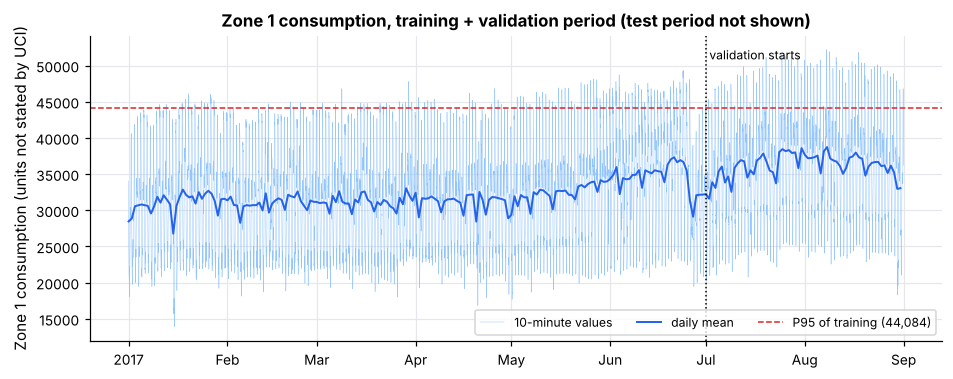

In [8]:
eda = df.loc[fc.SPLITS["train"][0]: fc.SPLITS["validation"][1]]
display(eda[["zone1"] + da.WEATHER_COLS].describe().T[["mean", "std", "min", "50%", "max"]])
fc.plot_time_series(eda, fc.SPLITS["validation"][0], thr);

**Figure 1: consumption over time.**
*Shows:* a large daily swing (roughly 20,000-45,000) on top of a slower level shift: daily means sit near 30-32k from January to April, then climb through May-June and reach roughly 35-38k in July-August. Values above the training P95 line become far more frequent from late spring onward.
*Does not prove:* why the level rises (the data contains no cause).
*Next step:* demand is **not stationary across the year**, so a model trained on Jan-Jun will meet higher levels in Jul-Aug. We keep that in mind when interpreting validation results.

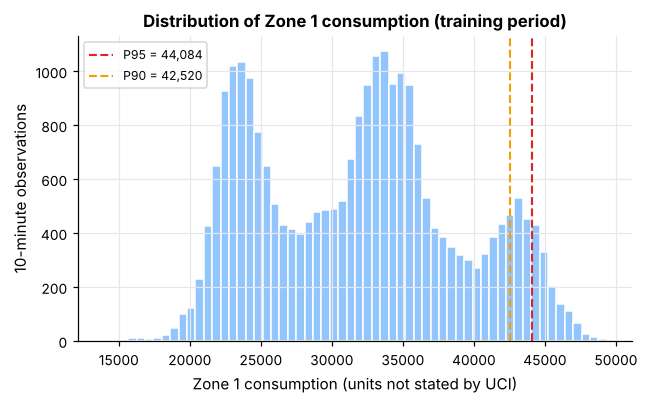

In [9]:
fc.plot_distribution(data[data.split == 'train']['target'], thresholds);

**Figure 2: distribution (training).** Shows where the P90 and P95 peak thresholds fall in the upper tail of training demand. It does not say peaks are errors or outliers; they are simply the highest-demand periods. *Next step:* these thresholds define peak vs non-peak in the error analysis.

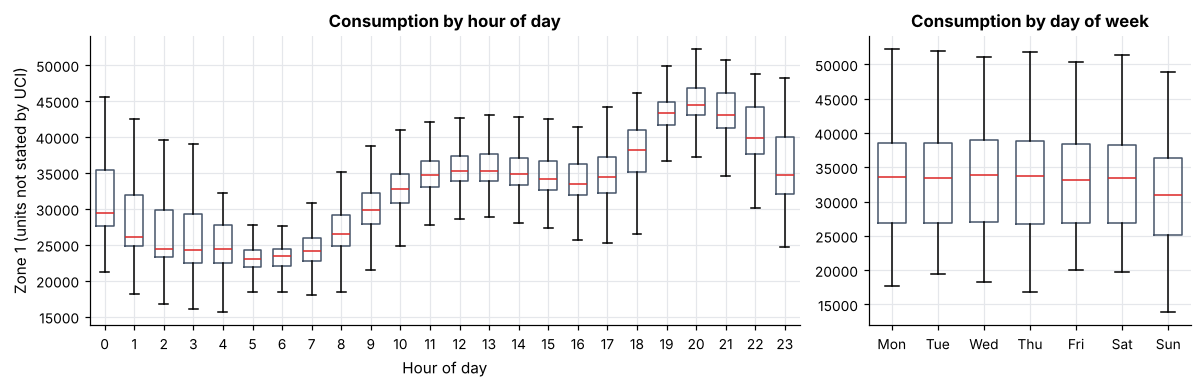

In [10]:
fc.plot_patterns(eda);

**Figure 3: hour of day and day of week.**
*Shows:* a strong daily cycle: the median is lowest in the early morning (about 23-24k between 03:00 and 07:00), plateaus around 34-35k at midday, then **rises sharply in the evening to its maximum around 20:00 (median about 44k)**. By weekday, Sunday is lower (median about 31k) than Monday-Saturday (about 33-34k).
*Does not prove:* what drives the evening rise (e.g. lighting or heating), since the data has no appliance or behaviour information.
*Next step:* calendar features and "same time yesterday" should be informative; the hardest moment to forecast is probably the **evening ramp-up**.

,Spearman rho with Zone 1
temperature,0.42
humidity,-0.30
wind_speed,0.09
general_diffuse_flows,0.23
diffuse_flows,0.09


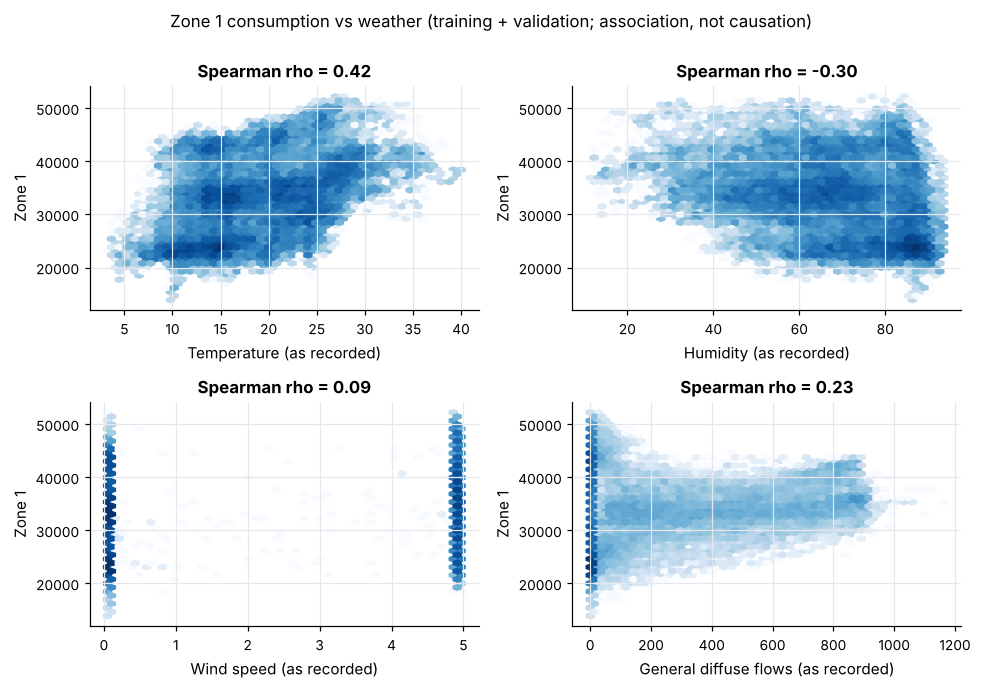

In [11]:
fc.plot_weather_relationships(eda);
display(eda[['zone1'] + da.WEATHER_COLS].corr(method='spearman')['zone1'].drop('zone1').to_frame('Spearman rho with Zone 1'))

**Figures 4-5: weather vs demand and correlations.**
*Shows:* weak-to-moderate monotonic associations: temperature (rho ≈ +0.4), humidity (≈ -0.3), general diffuse flows (≈ +0.2), wind speed and diffuse flows near zero.
*Does not prove causation.* Temperature, humidity and solar-type variables all follow the **time of day and season**, as does demand, so much of the association can be shared timing rather than a direct effect. Hexbin plots show density, not a fitted relationship.
*Next step:* the weather ablation (feature set A vs B) tests whether weather adds anything **after** time-of-day and recent demand are already known. That is the fair test of the research question.

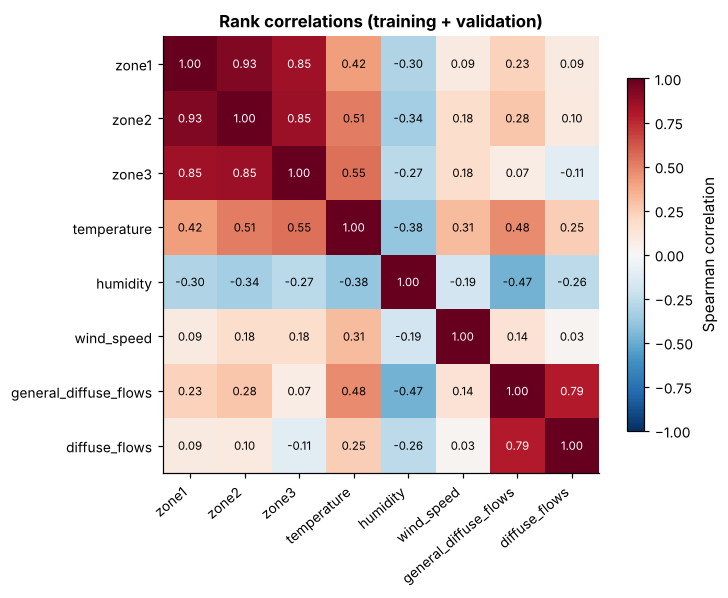

In [12]:
fc.plot_correlation(eda);

,ordinary,peak
zone1,"31,954.16","46,433.61"
temperature,18.77,22.71
humidity,67.93,65.25
wind_speed,1.96,2.98
general_diffuse_flows,221.13,13.43
diffuse_flows,94.14,13.07


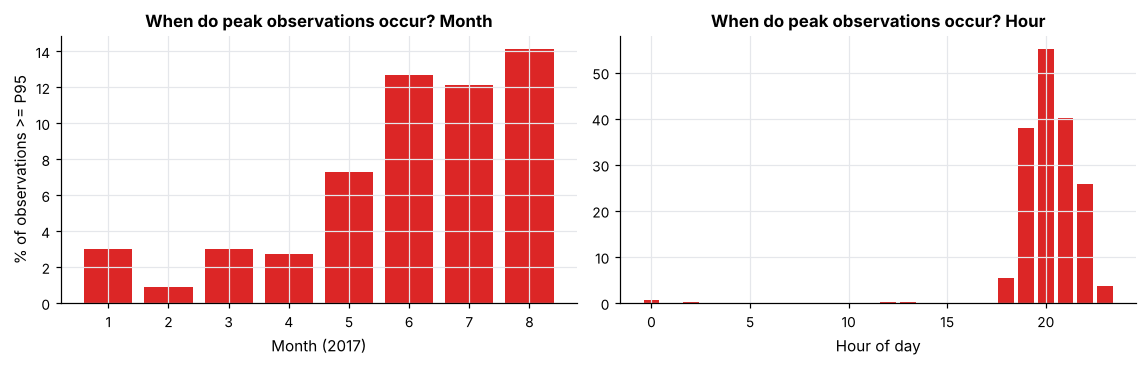

In [13]:
fc.plot_peak_profile(eda, thr);
pk_flag = eda["zone1"] >= thr
cmp = eda.assign(peak=pk_flag).groupby("peak")[["zone1"] + da.WEATHER_COLS].mean().T
cmp.columns = ["ordinary", "peak"]
display(cmp)

**Figure 6 and table: what are peak observations?**
*Shows:* peaks are **not random spikes**. They occur almost entirely in the evening (from 18:00 to 23:00, with about half of all 20:00 observations above the threshold) and mostly from May to August (roughly 7-14% of observations per month, versus 3% or less in Jan-Apr). On average, peak observations have higher temperature and **near-zero diffuse-flow readings** (consistent with after-dark hours).
*Does not prove:* that heat causes peaks; the weather contrast is confounded with the time of day.
*Next step:* "peak error" will largely mean "evening ramp-up in the warm season". Keep that in mind when reading the peak results.

## 5. Feature engineering

Every feature uses only information available at the forecast origin (verified by the perturbation test above). Feature set **A** = consumption history + calendar. Feature set **B** = A + weather observed at the origin. We deliberately did *not* add a day-of-year feature (one year of data cannot teach it) or holiday flags (not in the data).

In [14]:
feats = fc.feature_sets(groups)
ft = pd.DataFrame([{"feature": f, "in A": f in feats["A"], "in B": True, "why it might help": fc.FEATURE_NOTES[f]} for f in feats["B"]])
pd.set_option("display.max_colwidth", 120)
display(ft)
print(len(feats["A"]), "features in A;", len(feats["B"]), "in B")

,feature,in A,in B,why it might help
0,y_t,True,True,Latest observed Zone 1 consumption (the persistence signal).
1,y_lag_10m,True,True,Consumption 10 min earlier; with y_t gives very-short-term direction.
2,y_lag_30m,True,True,Consumption 30 min earlier.
3,y_lag_1h,True,True,Consumption 1 h earlier.
4,y_lag_2h,True,True,Consumption 2 h earlier; captures the slower trend.
5,y_same_time_yesterday,True,True,Consumption at the target's clock time on the previous day (t-23h).
6,change_30m,True,True,y_t minus the value 30 min earlier: recent momentum.
7,change_1h,True,True,y_t minus the value 1 h earlier: recent momentum over the horizon length.
8,roll_mean_1h,True,True,Mean of the last 6 observations (incl. t): denoised current level.
9,roll_std_1h,True,True,Std of the last 6 observations: short-term volatility.


18 features in A; 24 in B


## 6. Baselines and models

* **Persistence:** forecast = the latest observation `y_t`.
* **Same time yesterday:** forecast = consumption at the target's clock time on the previous day (observed 23 h before the origin, so it is available).
* **Ridge** (linear, standardised inputs), **Random Forest**, **HistGradientBoosting**: all from Scikit-learn with fixed, modest hyper-parameters (no tuning). `early_stopping=False` for boosting because the default would hold out a *random* slice of training rows, which is not valid for time series.
* Preprocessing (the Ridge scaler) is fitted inside a pipeline on training rows only.

**Metrics.** MAE and RMSE are in the same (unstated) units as the data; MAPE is a percentage of actual demand (safe here because demand never approaches zero). MAE is the average miss; RMSE penalises large misses more. **Percentage improvements below always name their baseline.**

Fitting takes roughly a minute.

In [15]:
preds, fitted = fc.fit_predict(data, feats, verbose=False)
table = fc.comparison_table(data, preds)
display(table.round(1))

,validation_MAE,validation_RMSE,validation_MAPE_%,test_MAE,test_RMSE,test_MAPE_%
model,,,,,,
Persistence (y_t),"2,411.10","3,197.20",6.80,"1,963.80","2,735.90",6.30
Same time yesterday,"1,423.20","2,116.20",4.00,"1,142.60","1,660.30",3.80
Ridge [A],"1,129.80","1,552.80",3.20,898.90,"1,234.10",2.90
RandomForest [A],"1,200.60","1,589.70",3.30,725.10,"1,021.50",2.40
HistGradientBoosting [A],"1,256.70","1,640.10",3.50,751.70,"1,021.90",2.50
Ridge [B],"1,117.10","1,535.90",3.20,915.10,"1,242.70",3.00
RandomForest [B],"1,181.00","1,565.00",3.30,709.00,"1,008.70",2.30
HistGradientBoosting [B],"1,359.60","1,749.30",3.80,729.00,993.10,2.50


In [16]:
cand = [n for n in table.index if "[" in n]
best = table.loc[cand, "validation_MAE"].idxmin()     # chosen on VALIDATION only
print("Model with the lowest validation MAE:", best)
imp = pd.DataFrame({
    "validation: % MAE reduction vs persistence": fc.pct_reduction(table.loc["Persistence (y_t)", "validation_MAE"], table.loc[cand, "validation_MAE"]),
    "validation: % vs same-time-yesterday": fc.pct_reduction(table.loc["Same time yesterday", "validation_MAE"], table.loc[cand, "validation_MAE"]),
    "test: % MAE reduction vs persistence": fc.pct_reduction(table.loc["Persistence (y_t)", "test_MAE"], table.loc[cand, "test_MAE"]),
    "test: % vs same-time-yesterday": fc.pct_reduction(table.loc["Same time yesterday", "test_MAE"], table.loc[cand, "test_MAE"]),
})
display(imp.round(1))

Model with the lowest validation MAE: Ridge [B]


,validation: % MAE reduction vs persistence,validation: % vs same-time-yesterday,test: % MAE reduction vs persistence,test: % vs same-time-yesterday
model,,,,
Ridge [A],53.10,20.60,54.20,21.30
RandomForest [A],50.20,15.60,63.10,36.50
HistGradientBoosting [A],47.90,11.70,61.70,34.20
Ridge [B],53.70,21.50,53.40,19.90
RandomForest [B],51.00,17.00,63.90,37.90
HistGradientBoosting [B],43.60,4.50,62.90,36.20


### Reading the comparison honestly

* All three learned models beat **both** baselines in both periods. Persistence is by far the weakest: it ignores the strong daily cycle. The "same time yesterday" baseline is much stronger and is the more meaningful bar to clear.
* **The ranking changes between validation and test.** On validation (models trained on Jan-Jun only) the linear model wins; on test (models refit on Jan-Aug) the tree models are clearly better. The selection rule was fixed in advance, so **the validation-selected model is reported as the primary model even though it is not the best on test.** We do not swap it after seeing test numbers.
* A plausible reason (checked on validation below, not on test): the Jan-Jun training data contains little high-demand data (only 5% of training targets are at or above the P95), while 13% of validation targets are. Tree models average the training cases that look similar and cannot extrapolate beyond them, so they should **under-forecast** (negative bias) on validation, and the problem should shrink once summer data is part of their training set.

In [17]:
va = data[data.split == "validation"]
rows = []
for name in ["Ridge [B]", "RandomForest [B]", "HistGradientBoosting [B]"]:
    p = fc.pred_lookup(data, preds, "validation", name)
    rows.append({"model": name, **{k: v for k, v in fc.metrics(va["target"], p).items() if k in ("MAE", "bias(pred-actual)")}})
display(pd.DataFrame(rows).set_index("model").round(1))
tr_max = data[data.split == "train"]["target"].max()
print(f"Training-period maximum target: {tr_max:,.0f}; share of validation targets above it: {(va['target'] > tr_max).mean() * 100:.1f}%")

,MAE,bias(pred-actual)
model,,
Ridge [B],"1,117.10",-57.40
RandomForest [B],"1,181.00",-430.00
HistGradientBoosting [B],"1,359.60",-396.90


Training-period maximum target: 49,361; share of validation targets above it: 2.6%


Tree models under-forecast on validation on average (negative bias) while the linear model does not, which is consistent with the thin-upper-tail explanation. Only a small share of validation targets (printed above) exceed the *maximum* training value, so this is about sparse upper-tail coverage rather than a hard range limit. It is a **hypothesis supported by the bias pattern, not a proven cause**, but it means validation-based model ranking should be treated with caution in this one-year dataset.

## 7. Peak vs non-peak error analysis (central question)

Groups use the **actual** target demand against the training-derived threshold. For each model we report the number of observations, MAE, RMSE and the **signed bias** (forecast - actual; negative = under-forecast). Because neighbouring 10-minute errors are strongly correlated, the effective sample size is closer to the number of *days* than to the number of rows, so confidence intervals come from a **day-block bootstrap** (resampling whole calendar days).

In [18]:
names = list(table.index)
pk = fc.peak_table(data, preds, names, thresholds)
t95 = pk[(pk.split == "test") & (pk.threshold == "P95")]
view = t95.pivot_table(index="model", columns="group", values=["n", "MAE", "RMSE", "bias(pred-actual)"]).reindex(names)
display(view[["n"]].iloc[:1].round(0).rename(columns=lambda c: c))
display(view[["MAE", "RMSE", "bias(pred-actual)"]].round(0))

n                 
group                   all  non-peak   peak
model                                       
Persistence (y_t) 17,418.00 16,607.00 811.00

MAE                       RMSE                   bias(pred-actual)                   
group                         all non-peak     peak      all non-peak     peak               all non-peak      peak
model                                                                                                              
Persistence (y_t)        1,964.00 1,891.00 3,447.00 2,736.00 2,560.00 5,156.00              1.00   126.00 -2,556.00
Same time yesterday      1,143.00 1,156.00   865.00 1,660.00 1,679.00 1,203.00             41.00    56.00   -263.00
Ridge [A]                  899.00   875.00 1,384.00 1,234.00 1,190.00 1,924.00            160.00   197.00   -598.00
RandomForest [A]           725.00   724.00   751.00 1,021.00 1,023.00   983.00            185.00   222.00   -565.00
HistGradientBoosting [A]   752.00   756.00   665.00 1,022.00 1,029.00   874.00            148.00   172.00   -348.00
Ridge [B]                  915.00   892.00 1,387.00 1,243.00 1,202.00 1,897.00            231.00   266.00   -494.00
RandomForest [B]           709.00   706.00   769.00 1,009.00 1,009.00   997.00            138.00   176.00   -625.00
HistGradientBoosting [B]   729.00   734.00   630.00   993.00 1,001.00   820.00             96.00   115.00   -286.00

In [19]:
d_te = data[data.split == "test"]
is_peak = (d_te["target"] >= thr).to_numpy()
gaps = pd.DataFrame([{"model": n, **fc.peak_gap_bootstrap(np.abs(fc.pred_lookup(data, preds, "test", n) - d_te["target"].to_numpy()), is_peak, d_te.index.normalize())} for n in names]).set_index("model")
print(f"Test: {is_peak.sum()} peak observations on {d_te.index[is_peak].normalize().nunique()} days; {(~is_peak).sum():,} non-peak observations")
display(gaps[["MAE_peak", "MAE_nonpeak", "gap", "gap_ci95_low", "gap_ci95_high", "ratio", "ratio_ci95_low", "ratio_ci95_high"]].round(2))

Test: 811 peak observations on 49 days; 16,607 non-peak observations


,MAE_peak,MAE_nonpeak,gap,gap_ci95_low,gap_ci95_high,ratio,ratio_ci95_low,ratio_ci95_high
model,,,,,,,,
Persistence (y_t),"3,447.06","1,891.37","1,555.69","1,398.52","1,706.48",1.82,1.73,1.91
Same time yesterday,864.95,"1,156.11",-291.15,-495.15,-76.50,0.75,0.59,0.93
Ridge [A],"1,384.33",875.22,509.11,410.58,609.04,1.58,1.45,1.73
RandomForest [A],751.17,723.79,27.38,-60.54,112.97,1.04,0.92,1.16
HistGradientBoosting [A],664.99,755.95,-90.96,-190.75,3.26,0.88,0.75,1.00
Ridge [B],"1,387.25",892.01,495.24,397.90,593.15,1.56,1.43,1.70
RandomForest [B],768.66,706.05,62.61,-27.72,149.79,1.09,0.96,1.21
HistGradientBoosting [B],629.74,733.82,-104.08,-195.82,-10.55,0.86,0.74,0.99


In [20]:
# Sensitivity: second threshold (P90) and the validation period
for split, pct in [("test", 90), ("validation", 95)]:
    s = pk[(pk.split == split) & (pk.threshold == f"P{pct}") & (pk.model.isin(["Persistence (y_t)", "Same time yesterday", "Ridge [B]", "RandomForest [B]", "HistGradientBoosting [B]"]))]
    print(f"--- {split}, peak = actual demand >= training P{pct} ({s['threshold_value'].iloc[0]:,.0f}); n_peak = {int(s[s.group=='peak']['n'].iloc[0])}")
    display(s.pivot_table(index="model", columns="group", values="MAE").round(0)[["peak", "non-peak", "all"]])

--- test, peak = actual demand >= training P90 (42,520); n_peak = 1020


group,peak,non-peak,all
model,,,
HistGradientBoosting [B],671.00,733.00,729.00
Persistence (y_t),"3,484.00","1,869.00","1,964.00"
RandomForest [B],768.00,705.00,709.00
Ridge [B],"1,379.00",886.00,915.00
Same time yesterday,921.00,"1,156.00","1,143.00"


--- validation, peak = actual demand >= training P95 (44,084); n_peak = 1173


group,peak,non-peak,all
model,,,
HistGradientBoosting [B],"1,626.00","1,319.00","1,360.00"
Persistence (y_t),"3,849.00","2,193.00","2,411.00"
RandomForest [B],"1,670.00","1,107.00","1,181.00"
Ridge [B],"1,530.00","1,055.00","1,117.00"
Same time yesterday,"1,234.00","1,452.00","1,423.00"


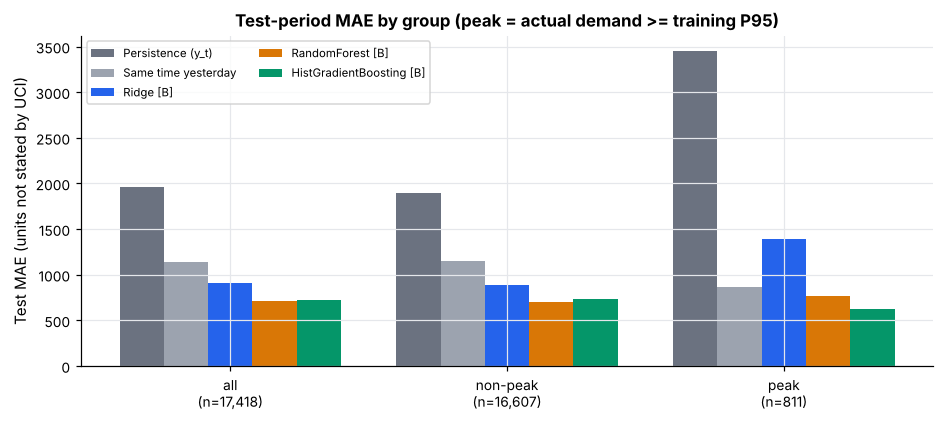

In [21]:
fc.plot_model_comparison(pk, list(dict.fromkeys(['Persistence (y_t)', 'Same time yesterday', best, 'Ridge [B]', 'RandomForest [B]', 'HistGradientBoosting [B]'])));

### Interpreting the peak results

* **Persistence is much worse in peak periods** (peak MAE ≈ 1.8× non-peak): during the evening ramp, "no change" is badly wrong.
* The picture for learned models **depends on the model**: the linear model's peak errors remain clearly larger than its non-peak errors (ratio ≈ 1.6, interval well above 1), while Random Forest shows no reliable difference and HistGradientBoosting is, if anything, slightly *better* on peaks (interval just below 1). Overall MAE can therefore hide a weakness for one model and not for another.
* **The strong simple baseline, "same time yesterday", has a lower peak MAE than the validation-selected Ridge model.** Peaks recur at similar times on consecutive days, so yesterday is a good guide exactly when the linear model struggles. Do not describe Ridge as "better on peaks" than this baseline.
* **Direction matters:** every model **under-forecasts peaks on average** (negative bias) and over-forecasts ordinary periods. Averages are pulled toward the middle, which is risky for planning, since the under-forecast is concentrated where capacity matters.
* **Stability check:** with the P90 threshold the test-period contrasts are essentially unchanged (same ordering and similar ratios). **On the validation period, however, every learned model had larger peak than non-peak errors** (ratios roughly 1.2-1.5, including Random Forest and boosting), so the tree models' lack of a peak penalty on test should **not** be assumed to hold in general. It depends on the period and on how much high-demand data the model was trained on.
* **Limits:** the peak definition is based on the training half-year, peaks are evening events concentrated on ~49 test days, and the interval ignores re-training variability.

## 8. Does weather help? (feature set A vs B)

Same models, same chronological splits, same target; the only difference is whether the six weather features are included. `A_minus_B_MAE > 0` means B (with weather) is better. The interval is a day-block bootstrap over evaluation days.

In [22]:
abl = fc.weather_ablation_table(data, preds, table, pk)
display(abl[["model", "split", "MAE_A", "MAE_B", "MAE_change_%_(B vs A)", "A_minus_B_MAE", "ci95_low", "ci95_high", "MAE_A_peak", "MAE_B_peak", "MAE_A_non-peak", "MAE_B_non-peak"]].round(1))

,model,split,MAE_A,MAE_B,MAE_change_%_(B vs A),A_minus_B_MAE,ci95_low,ci95_high,MAE_A_peak,MAE_B_peak,MAE_A_non-peak,MAE_B_non-peak
0,Ridge,validation,"1,129.80","1,117.10",-1.10,12.70,-2.90,28.40,"1,558.40","1,529.80","1,064.90","1,054.60"
1,Ridge,test,898.90,915.10,1.80,-16.10,-25.00,-6.40,"1,384.30","1,387.30",875.20,892.00
2,RandomForest,validation,"1,200.60","1,181.00",-1.60,19.70,5.40,34.50,"1,682.40","1,670.10","1,127.70","1,106.90"
3,RandomForest,test,725.10,709.00,-2.20,16.10,5.60,26.50,751.20,768.70,723.80,706.10
4,HistGradientBoosting,validation,"1,256.70","1,359.60",8.20,-103.00,-135.40,-72.00,"1,582.80","1,625.80","1,207.30","1,319.40"
5,HistGradientBoosting,test,751.70,729.00,-3.00,22.70,10.80,35.80,665.00,629.70,755.90,733.80


**Reading the ablation.** Changes are small (a few percent of MAE at most on test) and their **sign is not consistent**: weather helps Random Forest and HistGradientBoosting slightly on test, hurts Ridge slightly on test, and hurts HistGradientBoosting clearly on validation. Peak-period changes follow no stable pattern either. The intervals reflect only which days were sampled, not model re-fitting, so even "significant" entries should be read as tentative.

Overall, **in this dataset, weather observed at the forecast origin adds little once recent demand and the calendar are known.** That is plausible: the last hour of demand already encodes the current effect of weather, and we do not have genuine weather *forecasts* (future weather) which is where weather information would be expected to matter most.

### Permutation importance (validation, model fitted on training only)

,input,mae_increase_mean,mae_increase_std
0,[group] consumption_lags,"7,297.80",66.40
1,y_lag_10m,"3,192.90",14.50
2,y_same_time_yesterday,"3,122.90",11.30
3,y_t,"2,335.80",14.20
4,y_lag_30m,"2,107.60",18.70
5,y_lag_1h,"1,785.70",18.10
6,change_1h,678.90,5.60
7,roll_mean_1h,566.80,6.10
8,change_30m,372.30,6.50
9,[group] rolling_stats,345.10,8.00


,input,mae_increase_mean,mae_increase_std
0,[group] consumption_lags,"7,297.80",66.40
9,[group] rolling_stats,345.10,8.00
12,[group] calendar,273.60,4.30
16,[group] weather,55.20,2.00


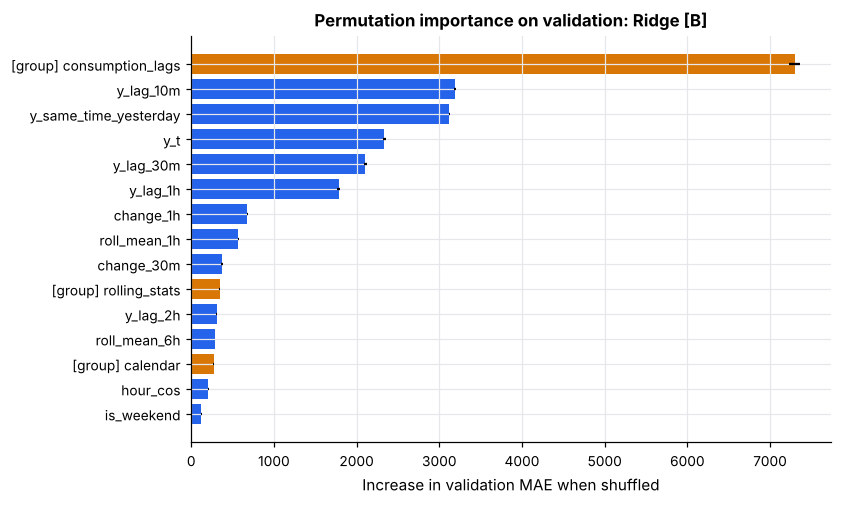

In [23]:
fs_best = best.rsplit(" [", 1)[1][:-1]; m_best = best.rsplit(" [", 1)[0]
va = data[data.split == "validation"]
pi = fc.permutation_importance_table(fitted[(m_best, fs_best)], va[feats[fs_best]], va["target"].to_numpy(), groups)
fc.plot_importance(pi, f"Permutation importance on validation: {best}");
display(pi.head(12).round(1))
display(pi[pi.input.str.startswith("[group]")].round(1))

Shuffling the consumption-history features raises validation MAE by far more than shuffling anything else, with the individual most-used inputs being the recent lags and "same time yesterday". The weather block's group importance is small by comparison. Permutation importance measures how much *this fitted model relies on* an input; **it is not evidence of causation**, and correlated inputs (e.g. several lags) share credit unevenly.

## 9. Error investigation (test period, validation-selected model)

We look at the largest absolute errors (worst 1% of test forecasts) and ask whether they are associated with large demand changes, particular hours or days, peak periods, or weather. "Actual change over the next hour" uses the future and is therefore **retrospective**; it helps describe the errors but is not a usable predictor.

In [24]:
e = fc.error_frame(data, preds, best, "test", thr)
display(fc.error_profile(e).round(2))
hr = e.assign(worst=e.abs_error >= e.abs_error.quantile(0.99))
by_hour = pd.DataFrame({"share of worst 1% (%)": hr[hr.worst].target_hour.value_counts(normalize=True).mul(100), "share of all forecasts (%)": hr.target_hour.value_counts(normalize=True).mul(100)}).fillna(0).sort_index()
print("Target hours with the most worst-1% errors:")
display(by_hour.sort_values("share of worst 1% (%)", ascending=False).head(6).round(1).T)
print("Month of the worst-1% forecasts vs all test forecasts (%):")
display(pd.DataFrame({"worst 1%": hr[hr.worst].index.month.value_counts(normalize=True).mul(100), "all forecasts": hr.index.month.value_counts(normalize=True).mul(100)}).fillna(0).sort_index().round(1).T)
print("Rank correlation, |error| vs |actual change next hour| (all test forecasts):", round(e[["abs_error", "abs_horizon_change"]].corr(method="spearman").iloc[0, 1], 2))

,other_99pct,worst_1pct
n,"17,243.00",175.00
mean_abs_error,877.26,"4,640.83"
mean_actual_demand,"31,027.61","35,905.19"
share_peak,0.04,0.30
mean_abs_change_next_hour,"1,925.15","5,772.64"
mean_abs_change_last_hour,"1,971.14","1,282.50"
mean_temperature,18.28,22.94
mean_humidity,69.40,59.28
mean_wind_speed,1.81,3.20
mean_diffuse_flows,47.74,89.47


Target hours with the most worst-1% errors:


target_hour,18,17,19,15,12,14
share of worst 1% (%),30.90,12.00,12.00,9.70,5.70,5.10
share of all forecasts (%),4.20,4.20,4.20,4.20,4.20,4.20


Month of the worst-1% forecasts vs all test forecasts (%):


datetime,9,10,11,12
worst 1%,53.10,29.70,8.00,9.10
all forecasts,24.80,25.60,24.80,24.80


Rank correlation, |error| vs |actual change next hour| (all test forecasts): 0.13


In [25]:
top = e.sort_values("abs_error", ascending=False).head(12)
display(pd.DataFrame({"origin": top.index, "target_time": top["target_time"].to_numpy(), "actual": top.target.round(0).to_numpy(), "forecast": top.pred.round(0).to_numpy(),
                      "persistence": top.persistence.round(0).to_numpy(), "error": top.error.round(0).to_numpy(), "actual_change_next_hour": top.horizon_change.round(0).to_numpy(),
                      "is_peak": top.is_peak.to_numpy(), "temperature": top.temperature.round(1).to_numpy()}))
display(e.groupby(e.index.normalize())["abs_error"].mean().sort_values(ascending=False).head(5).round(0).to_frame("mean abs error on that day"))

,origin,target_time,actual,forecast,persistence,error,actual_change_next_hour,is_peak,temperature
0,2017-11-22 13:10:00,2017-11-22 14:10:00,"25,545.00","33,584.00","32,246.00","8,039.00","-6,702.00",False,14.70
1,2017-10-18 08:30:00,2017-10-18 09:30:00,"27,445.00","34,508.00","31,151.00","7,063.00","-3,706.00",False,19.10
2,2017-11-22 13:20:00,2017-11-22 14:20:00,"26,412.00","33,059.00","31,932.00","6,647.00","-5,520.00",False,14.80
3,2017-11-22 14:10:00,2017-11-22 15:10:00,"29,674.00","23,624.00","25,545.00","-6,050.00","4,129.00",False,15.80
4,2017-09-01 13:10:00,2017-09-01 14:10:00,"27,016.00","33,038.00","28,112.00","6,022.00","-1,096.00",False,28.00
5,2017-10-18 08:40:00,2017-10-18 09:40:00,"28,750.00","34,578.00","31,573.00","5,828.00","-2,823.00",False,19.20
6,2017-10-06 14:30:00,2017-10-06 15:30:00,"30,502.00","36,273.00","35,820.00","5,772.00","-5,319.00",False,25.60
7,2017-09-02 18:00:00,2017-09-02 19:00:00,"40,811.00","35,134.00","31,546.00","-5,676.00","9,264.00",False,23.30
8,2017-09-30 14:10:00,2017-09-30 15:10:00,"27,035.00","32,701.00","31,317.00","5,666.00","-4,282.00",False,23.80
9,2017-10-09 17:10:00,2017-10-09 18:10:00,"45,866.00","40,221.00","34,604.00","-5,644.00","11,262.00",True,22.40


,mean abs error on that day
datetime,
2017-09-01,"2,598.00"
2017-12-01,"1,990.00"
2017-09-02,"1,760.00"
2017-10-25,"1,600.00"
2017-09-30,"1,503.00"


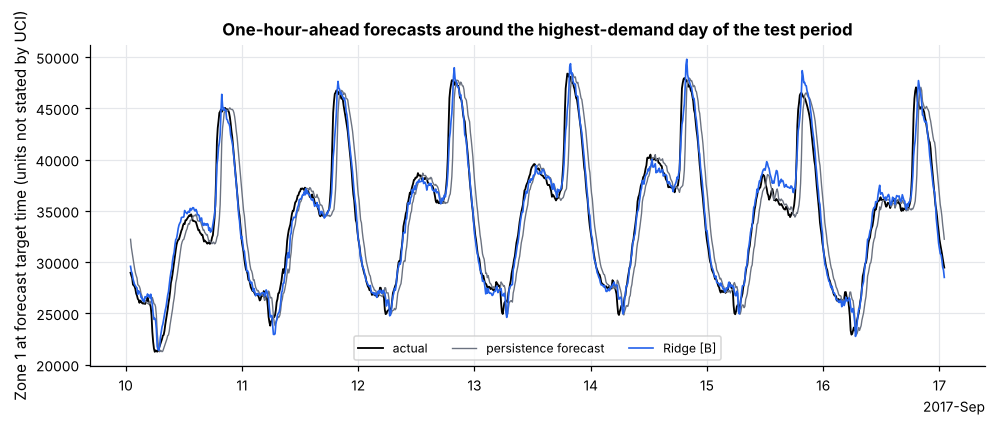

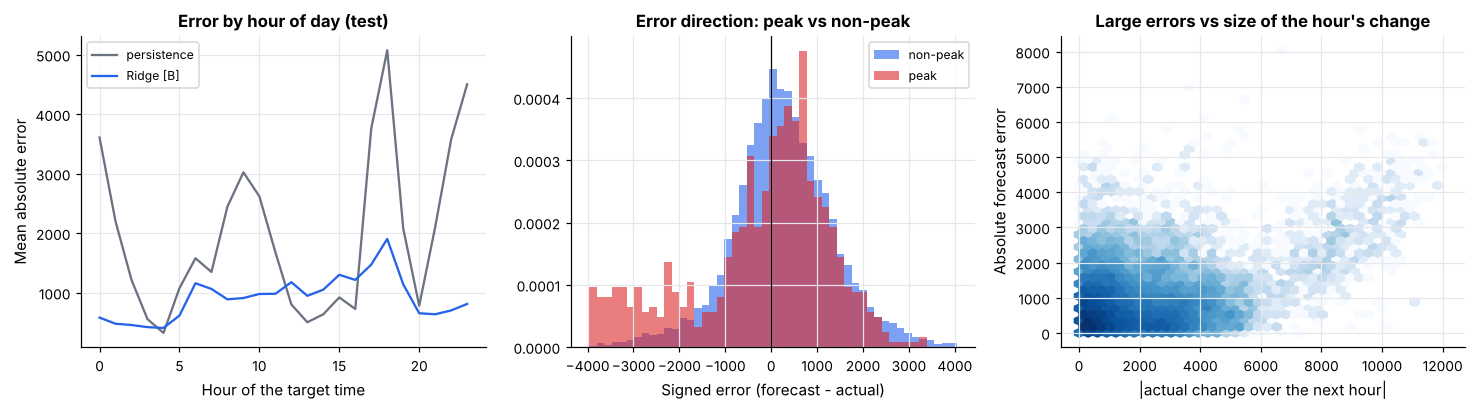

In [26]:
fc.plot_forecast_window(e, best);
fc.plot_error_diagnostics(e, best);

**What the error analysis shows.**
* The worst 1% of errors are **not spread evenly through the day**: more than half occur for targets between **17:00 and 19:00** (about 31% at 18:00 alone, versus ~4% expected if uniform), i.e. the evening ramp-up, plus a smaller cluster around 15:00 (about 10%).
* In those cases the **actual hour-ahead change is large** (mean around 5,800 versus about 1,900 for other forecasts) and the model's forecast stays close to the *current* level, so it misses sudden ramps (large under-forecasts before a rise) and sudden drops (over-forecasts before a fall, e.g. the 22 Nov afternoon drop). **Abrupt changes that the history does not hint at are the dominant failure mode.**
* The worst cases are far more likely to be peak observations (about 30% versus 4% for all other forecasts).
* The worst cases also have higher temperature, lower humidity and higher wind on average, but they are also concentrated in September-October (about 83% of the worst cases versus about 50% of all test forecasts) and in the evening, so this is an **association entangled with season and time of day**, not evidence that weather causes the errors. Overall, the rank correlation between error size and the size of the next hour's change is only weak (≈0.13): most forecasts are fine, and the large misses are a minority tail.
* **What this dataset cannot establish:** why demand ramps or drops abruptly (no event, outage, holiday or behaviour data), or whether these are measurement anomalies.

## 10. Conclusions (numbers generated from the results above)

In [27]:
def mae(n, sp): return table.loc[n, f"{sp}_MAE"]
b_name = best
print("Q1 - How accurate is a one-hour-ahead forecast?")
print(f"   Validation-selected model {b_name}: test MAE {mae(b_name,'test'):,.0f}, RMSE {table.loc[b_name,'test_RMSE']:,.0f}, MAPE {table.loc[b_name,'test_MAPE_%']:.1f}% (mean demand in test = {d_te.target.mean():,.0f}).")
bt = table.loc[cand, "test_MAE"].idxmin()
print(f"   Lowest test MAE among all candidates (NOT used for selection): {bt} = {mae(bt,'test'):,.0f}.")
print("Q2 - Better than baselines?")
print(f"   {b_name} vs persistence: {fc.pct_reduction(mae('Persistence (y_t)','test'), mae(b_name,'test')):.1f}% lower test MAE; vs same-time-yesterday: {fc.pct_reduction(mae('Same time yesterday','test'), mae(b_name,'test')):.1f}% lower.")
print("Q3 - Peak vs non-peak (test, P95):")
for n in ["Persistence (y_t)", "Same time yesterday", b_name, "RandomForest [B]", "HistGradientBoosting [B]"]:
    g = gaps.loc[n]
    print(f"   {n:28s} peak MAE {g.MAE_peak:6,.0f} | non-peak {g.MAE_nonpeak:6,.0f} | ratio {g.ratio:.2f} (95% CI {g.ratio_ci95_low:.2f}-{g.ratio_ci95_high:.2f}) | peak bias {t95[(t95.model==n)&(t95.group=='peak')]['bias(pred-actual)'].iloc[0]:+,.0f}")
print("Q4 - Weather (B vs A, test MAE change %):", {r.model: round(r["MAE_change_%_(B vs A)"], 1) for _, r in abl[abl.split == 'test'].iterrows()}, "| validation:", {r.model: round(r["MAE_change_%_(B vs A)"], 1) for _, r in abl[abl.split == 'validation'].iterrows()})

Q1 - How accurate is a one-hour-ahead forecast?
   Validation-selected model Ridge [B]: test MAE 915, RMSE 1,243, MAPE 3.0% (mean demand in test = 31,077).
   Lowest test MAE among all candidates (NOT used for selection): RandomForest [B] = 709.
Q2 - Better than baselines?
   Ridge [B] vs persistence: 53.4% lower test MAE; vs same-time-yesterday: 19.9% lower.
Q3 - Peak vs non-peak (test, P95):
   Persistence (y_t)            peak MAE  3,447 | non-peak  1,891 | ratio 1.82 (95% CI 1.73-1.91) | peak bias -2,556
   Same time yesterday          peak MAE    865 | non-peak  1,156 | ratio 0.75 (95% CI 0.59-0.93) | peak bias -263
   Ridge [B]                    peak MAE  1,387 | non-peak    892 | ratio 1.56 (95% CI 1.43-1.70) | peak bias -494
   RandomForest [B]             peak MAE    769 | non-peak    706 | ratio 1.09 (95% CI 0.96-1.21) | peak bias -625
   HistGradientBoosting [B]     peak MAE    630 | non-peak    734 | ratio 0.86 (95% CI 0.74-0.99) | peak bias -286
Q4 - Weather (B vs A, test

### Answers to the research questions

1. **Accuracy.** A one-hour-ahead Zone 1 forecast from simple, standard models misses by roughly 2-3% of demand on average in the test period (MAPE above). The units of MAE/RMSE are those of the raw data, which the source does not state.
2. **ML vs baselines.** Every learned model beats persistence by a wide margin and also beats the stronger "same time yesterday" baseline on overall MAE. The validation-selected model (Ridge with weather features) is **not** the most accurate on test; the tree models are, once summer data is in their training set.
3. **Peaks.** Persistence errors are much larger during peaks. On the test period the learned models are mixed: the linear model is clearly worse on peaks than off-peak and worse on peaks than "same time yesterday"; Random Forest shows no reliable gap; boosting is slightly better on peaks. **On the validation period all learned models were worse on peaks**, so the "no peak penalty" for tree models is not robust. All models **under-forecast peaks on average** in both periods. Peaks here are evening events in the warm season.
4. **Weather.** The measured effect of adding origin-time weather is small and inconsistent in sign. We cannot claim weather improves these forecasts; recent demand and the calendar carry nearly all the predictive signal. Largest errors are evening ramps and abrupt drops that history does not foreshadow.

### How this could inform planning or monitoring (not measured savings)
A deployed version could flag evening-ramp hours as high-risk for under-forecasting and could combine a learned model with "same time yesterday" as a safeguard in peak season. **We did not measure any cost, reliability or operational benefit.**

### Limitations
* **One city, three zones, one year (2017).** Seasonality, holidays and rare events appear at most once; results may not generalise to other cities, years or climates.
* **Split choice and distribution shift.** The split was chosen to make peak analysis possible; training lacks the summer months, which affects the validation ranking (trees under-forecast).
* **Hyper-parameters were not tuned**; different settings could change the model ranking.
* **No genuine weather forecasts.** Only observed weather at the origin was used; a separate experiment with forecast weather could behave differently.
* **Dependent errors.** Bootstrap intervals resample days but ignore re-training variability; the peak group is ~49 days.
* **Units not documented** by the source; two diffuse-flow variables are undefined.

### Next steps
Rolling-origin (walk-forward) evaluation across months, an additional year of data, tuned hyper-parameters selected on walk-forward folds, probabilistic/quantile forecasts for peaks, and a clearly labelled experiment using real weather forecasts. Zones 2 and 3 are an optional extension.